# Task 2

---

## Predictive modeling of customer bookings

This Jupyter notebook includes some code to get you started with this predictive modeling task. We will use various packages for data manipulation, feature engineering and machine learning.

### Exploratory data analysis

First, we must explore the data in order to better understand what we have and the statistical properties of the dataset.

# **EDA**

In [1]:
import pandas as pd

In [11]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import StratifiedKFold, KFold, cross_validate, train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import TargetEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.inspection import permutation_importance
from sklearn.metrics import (classification_report, confusion_matrix, ConfusionMatrixDisplay,
                             roc_auc_score, RocCurveDisplay)

pd.set_option("display.width", 200)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
NAVY, RED, GREY = "#0B1F45", "#C8102E", "#9AA3AF"
RANDOM_STATE = 42

In [3]:
df = pd.read_csv("data/customer_booking.csv", encoding="ISO-8859-1")
df.head()

,num_passengers,sales_channel,trip_type,purchase_lead,length_of_stay,flight_hour,flight_day,route,booking_origin,wants_extra_baggage,wants_preferred_seat,wants_in_flight_meals,flight_duration,booking_complete
0,2,Internet,RoundTrip,262,19,7,Sat,AKLDEL,New Zealand,1,0,0,5.52,0
1,1,Internet,RoundTrip,112,20,3,Sat,AKLDEL,New Zealand,0,0,0,5.52,0
2,2,Internet,RoundTrip,243,22,17,Wed,AKLDEL,India,1,1,0,5.52,0
3,1,Internet,RoundTrip,96,31,4,Sat,AKLDEL,New Zealand,0,0,1,5.52,0
4,2,Internet,RoundTrip,68,22,15,Wed,AKLDEL,India,1,0,1,5.52,0


The `.head()` method allows us to view the first 5 rows in the dataset, this is useful for visual inspection of our columns

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 14 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   num_passengers         50000 non-null  int64  
 1   sales_channel          50000 non-null  object 
 2   trip_type              50000 non-null  object 
 3   purchase_lead          50000 non-null  int64  
 4   length_of_stay         50000 non-null  int64  
 5   flight_hour            50000 non-null  int64  
 6   flight_day             50000 non-null  object 
 7   route                  50000 non-null  object 
 8   booking_origin         50000 non-null  object 
 9   wants_extra_baggage    50000 non-null  int64  
 10  wants_preferred_seat   50000 non-null  int64  
 11  wants_in_flight_meals  50000 non-null  int64  
 12  flight_duration        50000 non-null  float64
 13  booking_complete       50000 non-null  int64  
dtypes: float64(1), int64(8), object(5)
memory usage: 5.3+ 

The `.info()` method gives us a data description, telling us the names of the columns, their data types and how many null values we have. Fortunately, we have no null values. It looks like some of these columns should be converted into different data types, e.g. flight_day.

To provide more context, below is a more detailed data description, explaining exactly what each column means:

- `num_passengers` = number of passengers travelling
- `sales_channel` = sales channel booking was made on
- `trip_type` = trip Type (Round Trip, One Way, Circle Trip)
- `purchase_lead` = number of days between travel date and booking date
- `length_of_stay` = number of days spent at destination
- `flight_hour` = hour of flight departure
- `flight_day` = day of week of flight departure
- `route` = origin -> destination flight route
- `booking_origin` = country from where booking was made
- `wants_extra_baggage` = if the customer wanted extra baggage in the booking
- `wants_preferred_seat` = if the customer wanted a preferred seat in the booking
- `wants_in_flight_meals` = if the customer wanted in-flight meals in the booking
- `flight_duration` = total duration of flight (in hours)
- `booking_complete` = flag indicating if the customer completed the booking

Before we compute any statistics on the data, lets do any necessary data conversion

In [5]:
df["flight_day"].unique()

array(['Sat', 'Wed', 'Thu', 'Mon', 'Sun', 'Tue', 'Fri'], dtype=object)

In [6]:
mapping = {
    "Mon": 1,
    "Tue": 2,
    "Wed": 3,
    "Thu": 4,
    "Fri": 5,
    "Sat": 6,
    "Sun": 7,
}

df["flight_day"] = df["flight_day"].map(mapping)

In [7]:
df["flight_day"].unique()

array([6, 3, 4, 1, 7, 2, 5])

In [8]:
df.describe()

,num_passengers,purchase_lead,length_of_stay,flight_hour,flight_day,wants_extra_baggage,wants_preferred_seat,wants_in_flight_meals,flight_duration,booking_complete
count,50000.000000,50000.000000,50000.00000,50000.00000,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000
mean,1.591240,84.940480,23.04456,9.06634,3.814420,0.668780,0.296960,0.427140,7.277561,0.149560
std,1.020165,90.451378,33.88767,5.41266,1.992792,0.470657,0.456923,0.494668,1.496863,0.356643
min,1.000000,0.000000,0.00000,0.00000,1.000000,0.000000,0.000000,0.000000,4.670000,0.000000
25%,1.000000,21.000000,5.00000,5.00000,2.000000,0.000000,0.000000,0.000000,5.620000,0.000000
50%,1.000000,51.000000,17.00000,9.00000,4.000000,1.000000,0.000000,0.000000,7.570000,0.000000
75%,2.000000,115.000000,28.00000,13.00000,5.000000,1.000000,1.000000,1.000000,8.830000,0.000000
max,9.000000,867.000000,778.00000,23.00000,7.000000,1.000000,1.000000,1.000000,9.500000,1.000000


The `.describe()` method gives us a summary of descriptive statistics over the entire dataset (only works for numeric columns). This gives us a quick overview of a few things such as the mean, min, max and overall distribution of each column.

From this point, you should continue exploring the dataset with some visualisations and other metrics that you think may be useful. Then, you should prepare your dataset for predictive modelling. Finally, you should train your machine learning model, evaluate it with performance metrics and output visualisations for the contributing variables. All of this analysis should be summarised in your single slide.

In [9]:
print("Duplicate rows:", df.duplicated().sum())
print()
for col in ["sales_channel", "trip_type", "flight_day", "route", "booking_origin"]:
    print(f"{col}: {df[col].nunique()} unique values")
print()
print(df["booking_complete"].value_counts(normalize=True).rename("share").round(3))

Duplicate rows: 719

sales_channel: 2 unique values
trip_type: 3 unique values
flight_day: 7 unique values
route: 799 unique values
booking_origin: 104 unique values

booking_complete
0    0.85
1    0.15
Name: share, dtype: float64


Only about **15% of customers complete a booking**. So a model that always says "no booking" would already be 85% accurate. Accuracy alone is not a useful measure here, so I'll focus on recall, precision, F1 and ROC AUC.

`route` (799 values) and `booking_origin` (104 values) have far too many categories for one-hot encoding, so I'll use target encoding for those.

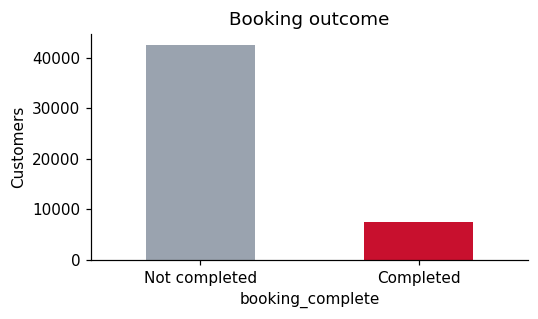

In [12]:
fig, ax = plt.subplots(figsize=(5, 3))
df["booking_complete"].value_counts().sort_index().plot.bar(color=[GREY, RED], ax=ax)
ax.set_xticklabels(["Not completed", "Completed"], rotation=0)
ax.set_ylabel("Customers"); ax.set_title("Booking outcome")
plt.tight_layout(); plt.show()

In [13]:
# Booking rate by customer and trip details

def rate(col):
    return df.groupby(col)["booking_complete"].agg(booking_rate="mean", customers="size").round(3)

for col in ["sales_channel", "trip_type", "wants_extra_baggage", "wants_preferred_seat",
            "wants_in_flight_meals", "num_passengers", "flight_day"]:
    print(rate(col), "\n")

               booking_rate  customers
sales_channel                         
Internet              0.155      44382
Mobile                0.108       5618 

            booking_rate  customers
trip_type                          
CircleTrip         0.043        116
OneWay             0.052        387
RoundTrip          0.151      49497 

                     booking_rate  customers
wants_extra_baggage                         
0                           0.115      16561
1                           0.167      33439 

                      booking_rate  customers
wants_preferred_seat                         
0                            0.138      35152
1                            0.177      14848 

                       booking_rate  customers
wants_in_flight_meals                         
0                             0.141      28643
1                             0.161      21357 

                booking_rate  customers
num_passengers                         
1                     

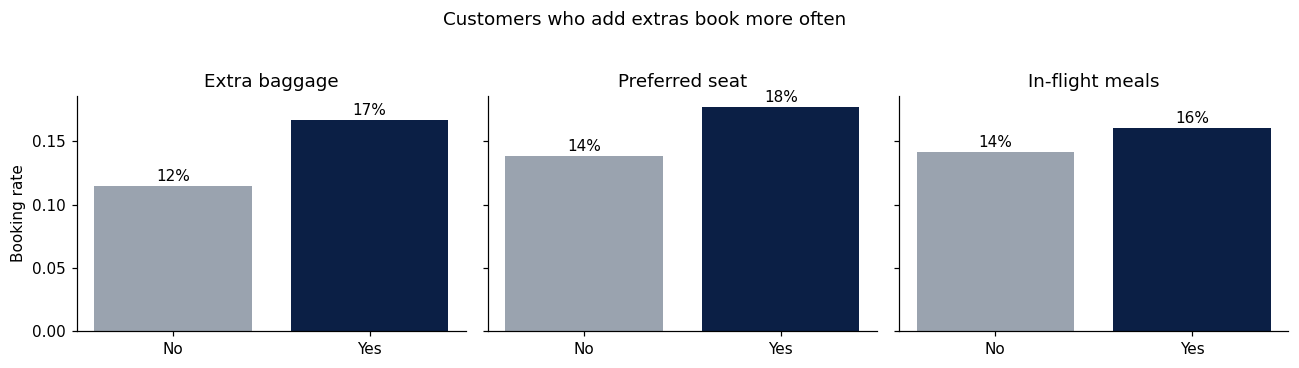

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.2), sharey=True)
for ax, col, label in zip(axes, ["wants_extra_baggage", "wants_preferred_seat", "wants_in_flight_meals"],
                          ["Extra baggage", "Preferred seat", "In-flight meals"]):
    r = df.groupby(col)["booking_complete"].mean()
    ax.bar(["No", "Yes"], r.values, color=[GREY, NAVY])
    ax.set_title(label)
    for i, v in enumerate(r.values): ax.text(i, v + 0.004, f"{v:.0%}", ha="center")
axes[0].set_ylabel("Booking rate")
plt.suptitle("Customers who add extras book more often", y=1.03)
plt.tight_layout(); plt.show()

Customers who add extras book more often, especially extra baggage (17% vs 12%). Mobile users book less than internet users, and one-way or circle trips rarely convert.

                booking_rate  customers
booking_origin                         
Australia              0.050      17872
Malaysia               0.344       7174
South Korea            0.101       4559
Japan                  0.123       3885
China                  0.205       3387
Indonesia              0.260       2369
Taiwan                 0.108       2077
Thailand               0.232       2030
India                  0.103       1270
New Zealand            0.050       1074


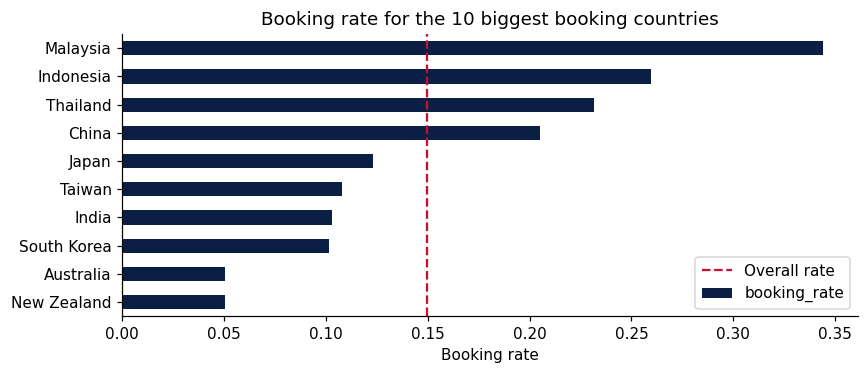

In [15]:
# Where customers book from

top = (df.groupby("booking_origin")["booking_complete"]
         .agg(booking_rate="mean", customers="size")
         .sort_values("customers", ascending=False).head(10))
print(top.round(3))

fig, ax = plt.subplots(figsize=(8, 3.5))
top["booking_rate"].sort_values().plot.barh(color=NAVY, ax=ax)
ax.axvline(df["booking_complete"].mean(), color=RED, ls="--", label="Overall rate")
ax.set_xlabel("Booking rate"); ax.set_ylabel(""); ax.legend()
ax.set_title("Booking rate for the 10 biggest booking countries")
plt.tight_layout(); plt.show()

Booking origin makes a huge difference. Australia is the biggest market (about 36% of customers) but only about 5% of them complete a booking. Malaysia converts at about 34%. This suggests origin will be a strong predictor.

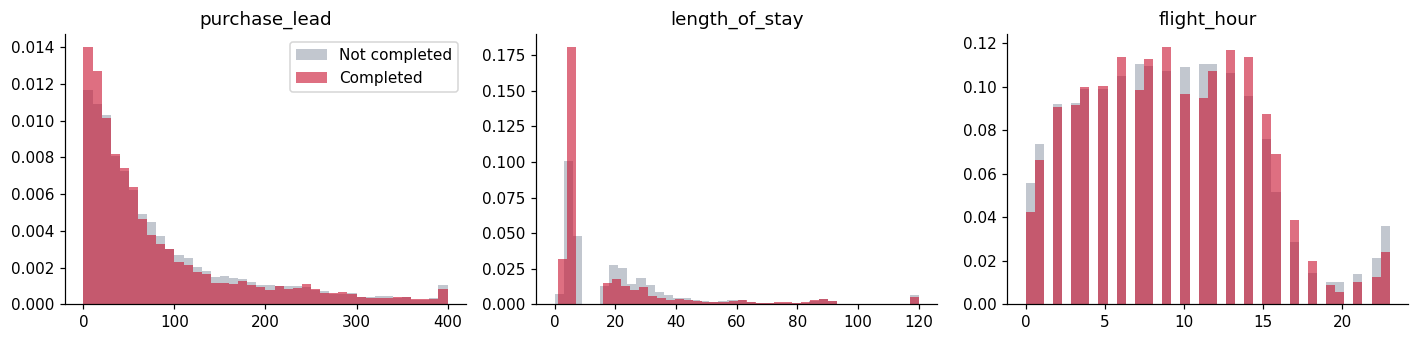

                  purchase_lead  length_of_stay  flight_hour  flight_duration
booking_complete                                                             
0                          52.0            17.0          9.0             7.57
1                          46.0             6.0          9.0             6.62


In [16]:
# Purchase lead, length of stay and flight time

fig, axes = plt.subplots(1, 3, figsize=(13, 3.2))
for ax, col, clip in zip(axes, ["purchase_lead", "length_of_stay", "flight_hour"], [400, 120, None]):
    for val, colr, lab in [(0, GREY, "Not completed"), (1, RED, "Completed")]:
        s = df.loc[df["booking_complete"] == val, col]
        if clip: s = s.clip(upper=clip)
        ax.hist(s, bins=40, density=True, alpha=0.6, color=colr, label=lab)
    ax.set_title(col)
axes[0].legend()
plt.tight_layout(); plt.show()

print(df.groupby("booking_complete")[["purchase_lead", "length_of_stay", "flight_hour", "flight_duration"]].median())

Completed bookings tend to have slightly shorter stays and shorter flights. `purchase_lead` and `length_of_stay` have long tails (up to 867 and 778 days). I'll keep them as they are, since Random Forests are not affected by outliers in the way linear models are.

# **Data Preparation**

- Remove the 719 duplicate rows
- Convert `flight_day` to numbers (Mon = 1 ... Sun = 7), as in the starter notebook
- Turn `sales_channel` and `trip_type` into 0/1 flags
- Create new features:
  - `total_extras`: number of extras chosen (0-3)
  - `is_weekend`: flight on Saturday or Sunday
  - `route_origin` and `route_dest`: the first and last three letters of `route`, so the model can learn about airports and not just exact routes
- Target-encode the high-cardinality columns (`route`, `booking_origin`, `route_origin`, `route_dest`). This happens inside the model pipeline, so the encoding is learned only from training folds and doesn't leak information from the test data.

In [17]:
data = df.drop_duplicates().reset_index(drop=True)
print("Rows after removing duplicates:", len(data))

data["flight_day"] = data["flight_day"].map({"Mon": 1, "Tue": 2, "Wed": 3, "Thu": 4, "Fri": 5, "Sat": 6, "Sun": 7})
data["is_mobile"] = (data["sales_channel"] == "Mobile").astype(int)
data["is_round_trip"] = (data["trip_type"] == "RoundTrip").astype(int)
data["total_extras"] = data[["wants_extra_baggage", "wants_preferred_seat", "wants_in_flight_meals"]].sum(axis=1)
data["is_weekend"] = data["flight_day"].isin([6, 7]).astype(int)
data["route_origin"] = data["route"].str[:3]
data["route_dest"] = data["route"].str[3:]

X = data.drop(columns=["booking_complete", "sales_channel", "trip_type"])
y = data["booking_complete"]
cat_cols = ["route", "booking_origin", "route_origin", "route_dest"]
print("Features:", list(X.columns))

Rows after removing duplicates: 49281
Features: ['num_passengers', 'purchase_lead', 'length_of_stay', 'flight_hour', 'flight_day', 'route', 'booking_origin', 'wants_extra_baggage', 'wants_preferred_seat', 'wants_in_flight_meals', 'flight_duration', 'is_mobile', 'is_round_trip', 'total_extras', 'is_weekend', 'route_origin', 'route_dest']


# **Train a Random Forest**

I compare two versions:
- **Default Random Forest**
- **Balanced Random Forest**: `class_weight="balanced_subsample"` gives more weight to the smaller "completed" class, and `min_samples_leaf=5` stops the trees from memorising individual customers

Both use the same pipeline (target encoding, then the forest) and are scored with stratified 5-fold cross-validation.

In [20]:
from sklearn.model_selection import StratifiedKFold, cross_validate, train_test_split

# def make_pipeline(rf):
#     encoder = TargetEncoder(cv=5)
#     pre = ColumnTransformer([("target_enc", encoder, cat_cols)],
#                             remainder="passthrough", verbose_feature_names_out=False)
#     return Pipeline([("prep", pre), ("rf", rf)])
def make_pipeline(rf):
    encoder = TargetEncoder(cv=5, shuffle=True, random_state=RANDOM_STATE)
    pre = ColumnTransformer([("target_enc", encoder, cat_cols)],
                            remainder="passthrough", verbose_feature_names_out=False)
    return Pipeline([("prep", pre), ("rf", rf)])

models = {
    "Default RF": RandomForestClassifier(n_estimators=300, n_jobs=-1, random_state=RANDOM_STATE),
    "Balanced RF": RandomForestClassifier(n_estimators=300, min_samples_leaf=5,
                                          class_weight="balanced_subsample",
                                          n_jobs=-1, random_state=RANDOM_STATE),
}
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
metrics = ["accuracy", "precision", "recall", "f1", "roc_auc"]

results = {}
for name, rf in models.items():
    scores = cross_validate(make_pipeline(rf), X, y, cv=cv, scoring=metrics)
    results[name] = {m: f"{scores['test_' + m].mean():.3f} ± {scores['test_' + m].std():.3f}" for m in metrics}

# baseline: always predict "no booking"
results["Baseline (always 'no')"] = {"accuracy": f"{1 - y.mean():.3f}", "precision": "0.000",
                                     "recall": "0.000", "f1": "0.000", "roc_auc": "0.500"}
cv_table = pd.DataFrame(results).T
cv_table

,accuracy,precision,recall,f1,roc_auc
Default RF,0.848 ± 0.001,0.473 ± 0.014,0.113 ± 0.006,0.182 ± 0.007,0.787 ± 0.002
Balanced RF,0.806 ± 0.003,0.385 ± 0.007,0.495 ± 0.006,0.433 ± 0.006,0.796 ± 0.003
Baseline (always 'no'),0.850,0.000,0.000,0.000,0.500


**What this shows:**
- The default model is about 85% accurate, but that's the same as the baseline. It only catches about 10% of real bookings, so it's mostly predicting "no".
- The balanced model gives up a little accuracy but catches nearly **half of all bookings** (recall about 0.48), and its F1 score is much higher.
- Both have a **ROC AUC of about 0.80**, so the data has real predictive power: the model ranks a booker above a non-booker about 80% of the time.

I'll use the balanced model from here on.

# **Evaluate on a hold-out test set**

In [21]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)
final_model = make_pipeline(models["Balanced RF"]).fit(X_train, y_train)

pred = final_model.predict(X_test)
prob = final_model.predict_proba(X_test)[:, 1]
print(classification_report(y_test, pred, target_names=["Not completed", "Completed"], digits=3))
print("ROC AUC:", round(roc_auc_score(y_test, prob), 3))

               precision    recall  f1-score   support

Not completed      0.904     0.859     0.881      8379
    Completed      0.378     0.486     0.425      1478

     accuracy                          0.803      9857
    macro avg      0.641     0.672     0.653      9857
 weighted avg      0.826     0.803     0.813      9857

ROC AUC: 0.789


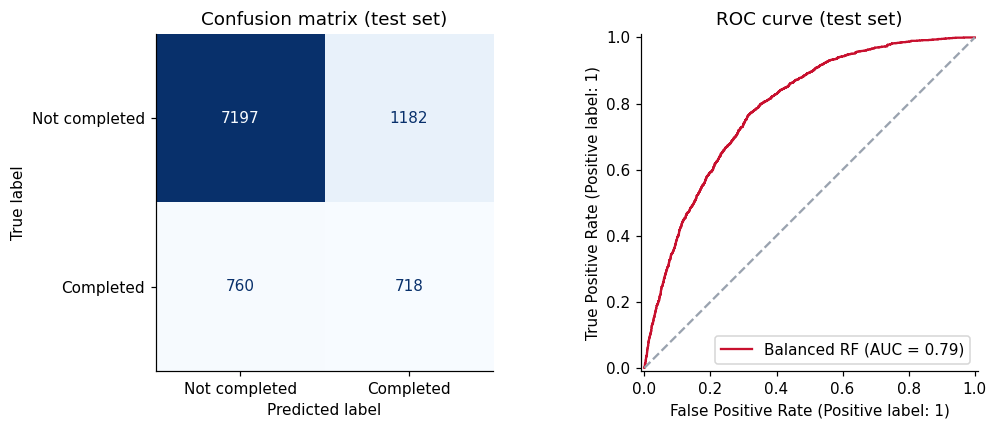

In [24]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
ConfusionMatrixDisplay.from_predictions(y_test, pred, display_labels=["Not completed", "Completed"],
                                        cmap="Blues", colorbar=False, ax=axes[0])
axes[0].set_title("Confusion matrix (test set)")
RocCurveDisplay.from_predictions(y_test, prob, ax=axes[1], color=RED, name="Balanced RF")
axes[1].plot([0, 1], [0, 1], ls="--", color=GREY); axes[1].set_title("ROC curve (test set)")
plt.tight_layout(); plt.savefig("images/evaluation.png", bbox_inches="tight"); plt.show()

The test-set results match cross-validation, so the model isn't overfitting. It correctly flags 47% of the customers who go on to book (692 of 1,478), and when it predicts a booking, it's right 38% of the time. That's well above the 15% you'd get by guessing at random.

# **How each variable contributes**

I use **permutation importance** on the test set. It shuffles one variable at a time and measures how much ROC AUC drops. It's more reliable than the Random Forest's built-in importance, which tends to overrate numeric columns with many unique values (like `purchase_lead`). The built-in version is shown afterwards for comparison.

In [25]:
perm = permutation_importance(final_model, X_test, y_test, scoring="roc_auc",
                              n_repeats=5, random_state=RANDOM_STATE, n_jobs=-1)
imp = (pd.DataFrame({"feature": X_test.columns, "importance": perm.importances_mean, "std": perm.importances_std})
         .sort_values("importance", ascending=False).reset_index(drop=True))
imp.round(4)

,feature,importance,std
0,booking_origin,0.1036,0.0019
1,route,0.0577,0.0027
2,length_of_stay,0.0118,0.0019
3,route_origin,0.0091,0.0007
4,is_mobile,0.0068,0.0007
5,route_dest,0.0064,0.0011
6,purchase_lead,0.0053,0.0010
7,total_extras,0.0041,0.0009
8,wants_extra_baggage,0.0030,0.0006
9,flight_duration,0.0030,0.0006


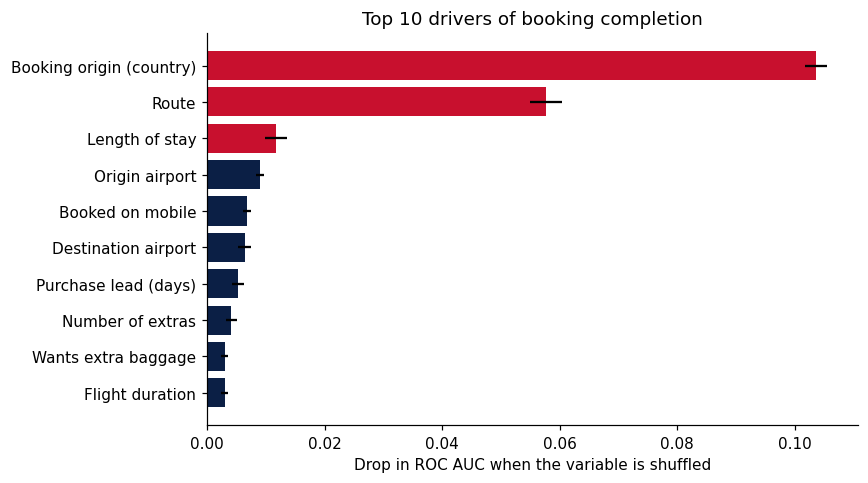

In [26]:
labels = {
    "booking_origin": "Booking origin (country)", "route": "Route", "route_dest": "Destination airport",
    "route_origin": "Origin airport", "length_of_stay": "Length of stay", "flight_duration": "Flight duration",
    "purchase_lead": "Purchase lead (days)", "flight_hour": "Flight hour", "wants_extra_baggage": "Wants extra baggage",
    "total_extras": "Number of extras", "wants_in_flight_meals": "Wants in-flight meals",
    "wants_preferred_seat": "Wants preferred seat", "num_passengers": "Number of passengers",
    "flight_day": "Flight day", "is_mobile": "Booked on mobile", "is_round_trip": "Round trip", "is_weekend": "Weekend flight",
}
top10 = imp.head(10).iloc[::-1]
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.barh(top10["feature"].map(labels), top10["importance"], xerr=top10["std"],
        color=[RED if i >= len(top10) - 3 else NAVY for i in range(len(top10))])
ax.set_xlabel("Drop in ROC AUC when the variable is shuffled")
ax.set_title("Top 10 drivers of booking completion")
plt.tight_layout(); plt.savefig("images/feature_importance.png", bbox_inches="tight", dpi=200); plt.show()

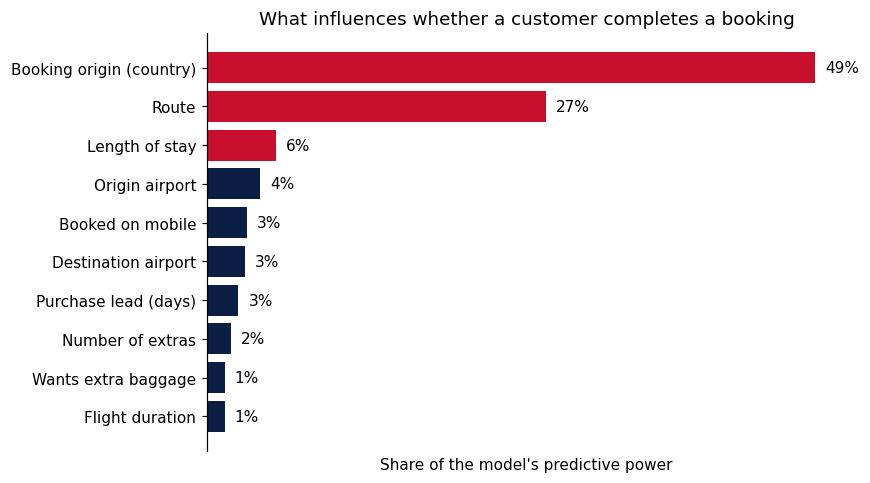

In [28]:
# share of total importance, so the bars add up to 100%
pos = imp[imp["importance"] > 0].copy()
pos["share"] = pos["importance"] / pos["importance"].sum() * 100
top10 = pos.head(10).iloc[::-1]

fig, ax = plt.subplots(figsize=(8, 4.5))
bars = ax.barh(top10["feature"].map(labels), top10["share"],
               color=[RED if i >= len(top10) - 3 else NAVY for i in range(len(top10))])
for bar, v in zip(bars, top10["share"]):
    ax.text(v + 0.8, bar.get_y() + bar.get_height() / 2, f"{v:.0f}%", va="center")

ax.set_title("What influences whether a customer completes a booking")
ax.set_xlabel("Share of the model's predictive power")
ax.set_xticks([])                       # hide the number scale, the labels show the values
ax.spines["bottom"].set_visible(False)
plt.tight_layout(); plt.savefig("images/feature_importance.png", bbox_inches="tight", dpi=200); plt.show()

In [27]:
builtin = pd.Series(final_model.named_steps["rf"].feature_importances_,
                    index=final_model.named_steps["prep"].get_feature_names_out()).sort_values(ascending=False)
builtin.round(3).head(10)

,0
booking_origin,0.207
route,0.201
route_origin,0.116
purchase_lead,0.101
route_dest,0.092
length_of_stay,0.080
flight_hour,0.071
flight_duration,0.040
total_extras,0.023
num_passengers,0.023


# **Findings**

- **The data is moderately predictive.** ROC AUC is about 0.80 in 5-fold cross-validation and 0.79 on the test set. The model catches about 47% of real bookings, and 38% of the customers it flags go on to book, compared with the 15% base rate.
- **Where the customer books from matters most, by far.** Booking origin is the strongest driver, followed by route. Conversion varies hugely by market, for example about 5% from Australia vs about 34% from Malaysia.
- **Length of stay comes next**, followed by origin airport, sales channel (mobile users book less), destination airport and purchase lead.
- **Extras matter, but only a little.** Customers who add extras, especially baggage, book more often, but these add much less to the model than location.
- **Some variables add almost nothing**: flight hour, flight day, weekend flag, number of passengers and in-flight meals.
- **Accuracy is misleading here.** A model that always says "no" is 85% accurate, so recall, F1 and AUC are better measures.

**Limitations:** only 14 columns. There's no data on price, previous bookings or how customers browsed the site, which would probably improve predictions a lot. The probability threshold (0.5) could also be tuned, depending on whether BA cares more about catching every possible booker or about precision.